<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta5_g%C3%B6rev1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: NVIDIA RTX PRO 6000 Blackwell Server Edition


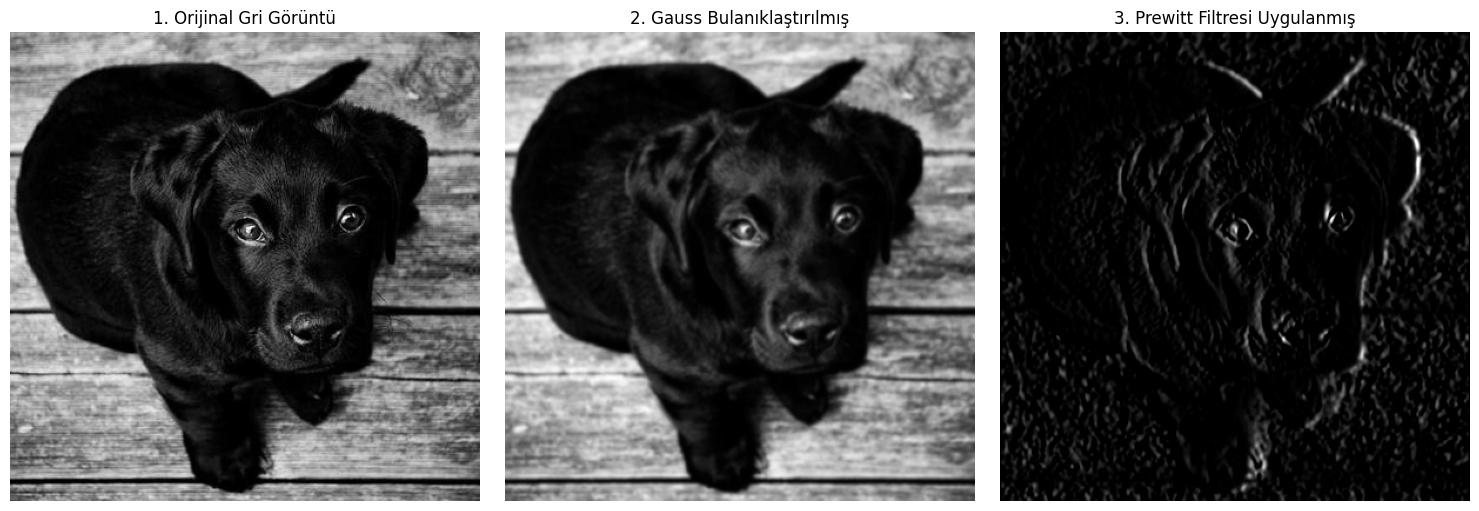

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

# 1. Test için örnek bir görüntü indirelim
url = 'https://picsum.photos/id/237/400/400'
req = urllib.request.urlopen(url)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
img = cv2.imdecode(arr, cv2.IMREAD_GRAYSCALE)

# 2. Gauss Filtresi ile Görüntüyü Hafif Yumuşatma (Gürültüyü azaltmak için)
# (5, 5) kernel boyutu ve standart sapma ile yumuşatma yapıyoruz
blurred_img = cv2.GaussianBlur(img, (5, 5), 0)

# 3. Verilen 3x3 Prewitt Filtresi (Yatay türev / Dikey kenar tespiti)
prewitt_kernel = np.array([
    [-1,  0,  1],
    [-1,  0,  1],
    [-1,  0,  1]
], dtype=np.float32)

# 4. Filtreyi görüntü üzerinde uygulama
filtered_img = cv2.filter2D(blurred_img, -1, prewitt_kernel)

# 5. Sonuçları Görselleştirme
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('1. Orijinal Gri Görüntü')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(blurred_img, cmap='gray')
plt.title('2. Gauss Bulanıklaştırılmış')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(filtered_img, cmap='gray')
plt.title('3. Prewitt Filtresi Uygulanmış')
plt.axis('off')

plt.tight_layout()
plt.show()